# EDA - Credit Card Fraud Detection (`001_eda.ipynb`)

## Block 1: Data Quality, Duplicates, and Structural Integrity

In this first block of the Exploratory Data Analysis (EDA), we investigate:
1. **Basic Integrity and Temporal Ordering:** Dataset dimensions, missing values, data types, and monotonicity of the `Time` column.
2. **Exact Duplicates (all 31 columns):** Global and class-stratified quantification (`Legitimate` vs. `Fraud`), as well as repetition multiplicity within the exact same second.
3. **Temporal Near-Duplicates (same `V1..V28` and `Amount` features, but different `Time`):** Behavioral contrast between legitimate retries/recurring charges and fraud attacks.
4. **Label Consistency (*Label Noise*):** Verification of identical transactions with contradictory class labels.
5. **Amount Anomalies (`Amount == 0.00` - *Zero-Dollar Auth*):** Discovery of card verification/probing patterns used by fraudsters.
6. **Engineering Decision and *Data Leakage* Prevention:** How to handle duplicates in the training and validation pipeline.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix
)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 35)

DATA_PATH = Path("../data/processed/creditcard.parquet")
df = pd.read_parquet(DATA_PATH)

print(f"Dataset dimensions   : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"RAM memory usage     : {df.memory_usage().sum() / (1024**2):.2f} MB")
print(f"Total NaN values     : {df.isna().sum().sum()}")
print(f"Time monotonic incr. : {df['Time'].is_monotonic_increasing} (min={df['Time'].min()}s, max={df['Time'].max()}s / ~48h)")
print("\nOriginal target variable distribution (Class):")
class_summary = pd.DataFrame({
    "Count": df["Class"].value_counts(),
    "Percentage (%)": df["Class"].value_counts(normalize=True) * 100
})
print(class_summary.round(4))

Dataset dimensions   : 284,807 rows x 31 columns
RAM memory usage     : 65.46 MB
Total NaN values     : 0
Time monotonic incr. : True (min=0.0s, max=172792.0s / ~48h)

Original target variable distribution (Class):
        Count  Percentage (%)
Class                        
0      284315         99.8273
1         492          0.1727


### 1.1. Exact Duplicates Investigation (All 31 Columns Identical)

An **exact duplicate** means that `Time`, `V1` through `V28`, `Amount`, and `Class` are 100% identical — that is, the exact same transaction was logged more than once within the **exact same second**.

In [2]:
# Counting exact duplicates
exact_dup_mask = df.duplicated(keep="first")
all_involved_mask = df.duplicated(keep=False)

dup_by_class = df[exact_dup_mask]["Class"].value_counts()
total_by_class = df["Class"].value_counts()
unique_by_class = df.drop_duplicates()["Class"].value_counts()

dup_report = pd.DataFrame({
    "Gross Total": total_by_class,
    "Excess Duplicates (keep='first')": dup_by_class,
    "Remaining Unique Rows": unique_by_class,
    "% Duplicated in Class": (dup_by_class / total_by_class * 100).round(2)
})
dup_report.index = ["0 - Legitimate", "1 - Fraud"]

print(f"Total excess rows (exact duplicates)           : {exact_dup_mask.sum():,}")
print(f"Total rows involved in duplication             : {all_involved_mask.sum():,} (grouped into 773 distinct transactions)")
print(f"Dataset after removing exact duplicates        : {len(df.drop_duplicates()):,} rows\n")
print(dup_report)

Total excess rows (exact duplicates)           : 1,081
Total rows involved in duplication             : 1,854 (grouped into 773 distinct transactions)
Dataset after removing exact duplicates        : 283,726 rows

                Gross Total  Excess Duplicates (keep='first')  \
0 - Legitimate       284315                              1062   
1 - Fraud               492                                19   

                Remaining Unique Rows  % Duplicated in Class  
0 - Legitimate                 283253                   0.37  
1 - Fraud                         473                   3.86  


### 1.2. Exact Duplicate Multiplicity (How many times does the same row repeat?)

Beyond knowing there are `1,081` excess copies, it is important to check whether they are simply pairs (2x) or simultaneous logging *bursts* in the banking system.

In [3]:
grp_all = df.groupby(list(df.columns)).size()
dup_groups_all = grp_all[grp_all > 1]

grp_fraud = df[df["Class"] == 1].groupby(list(df.columns)).size()
dup_groups_fraud = grp_fraud[grp_fraud > 1]

print("Duplicate group size distribution (Overall - 773 groups):")
print(dup_groups_all.value_counts().sort_index().rename_axis("Repetitions in the same second").to_frame("Group Count"))

print("\nDuplicate group size distribution (Frauds Only - 13 groups = 19 excess rows):")
print(dup_groups_fraud.value_counts().sort_index().rename_axis("Repetitions in the same second").to_frame("Fraud Group Count"))

Duplicate group size distribution (Overall - 773 groups):
                                Group Count
Repetitions in the same second             
2                                       611
3                                        66
4                                        81
5                                        10
6                                         1
9                                         2
18                                        2

Duplicate group size distribution (Frauds Only - 13 groups = 19 excess rows):
                                Fraud Group Count
Repetitions in the same second                   
2                                              11
4                                               1
6                                               1


### 1.3. Additional Deep-Dive Analyses: Temporal Near-Duplicates, Label Conflicts, and *Zero-Dollar Auth* (`Amount == 0`)

To go beyond standard checks, we investigate three critical phenomena in payment systems data:
1. **Near-Duplicates (`V1..V28` and `Amount` identical, but different `Time`):** Occur when the same card performs the exact same transaction at different moments.
2. **Label Conflicts (*Label Noise*):** Are there any transactions with the exact same features (`V1..V28` + `Amount`), but labeled both as `0` and as `1`?
3. **Zero-Value Transactions (`Amount == 0.00`):** Fraudsters frequently test whether a card is active using zero-dollar charges (*Zero-Auth* / card verification) before executing real purchases.

In [4]:
feature_cols = [c for c in df.columns if c not in ["Time", "Class"]]

# 1. Near-duplicates (ignoring Time)
quasi_dup_mask = df.duplicated(subset=feature_cols, keep="first")
quasi_by_class = df[quasi_dup_mask]["Class"].value_counts()

# 2. Label conflicts (same V1..V28 + Amount with both Class 0 and 1)
label_conflicts = (df.groupby(feature_cols)["Class"].nunique() > 1).sum()

# 3. Transactions with Amount == 0 or Amount < 0
neg_amount_count = (df["Amount"] < 0).sum()
zero_amount_df = df[df["Amount"] == 0]
zero_by_class = zero_amount_df["Class"].value_counts()

print(f"1) Duplicates ignoring 'Time' (same V1..V28 + Amount)   : {quasi_dup_mask.sum():,}")
print(f"   - In legitimate transactions (Class=0)               : {quasi_by_class.get(0, 0):,} (1,062 in same sec + 8,063 in diff secs)")
print(f"   - In fraudulent transactions (Class=1)               : {quasi_by_class.get(1, 0):,} (all 19 occur in the EXACT same second!)\n")

print(f"2) Label conflicts (same features, Class 0 vs 1)        : {label_conflicts}\n")

print(f"3) 'Amount' value verification:")
print(f"   - Transactions with Amount < 0                       : {neg_amount_count}")
print(f"   - Transactions with Amount == 0.00 (Zero-Auth)       : {len(zero_amount_df):,}")
print(f"     * Legitimate (Class=0) with Amount == 0            : {zero_by_class.get(0, 0):,} ({zero_by_class.get(0, 0)/total_by_class[0]*100:.2f}% of legitimate)")
print(f"     * Frauds     (Class=1) with Amount == 0            : {zero_by_class.get(1, 0):,} ({zero_by_class.get(1, 0)/total_by_class[1]*100:.2f}% of frauds!)")
print(f"     * Fraud Rate when Amount == 0                      : {zero_by_class.get(1, 0)/len(zero_amount_df)*100:.4f}% (~8.6x higher than dataset average!)")

1) Duplicates ignoring 'Time' (same V1..V28 + Amount)   : 9,144
   - In legitimate transactions (Class=0)               : 9,125 (1,062 in same sec + 8,063 in diff secs)
   - In fraudulent transactions (Class=1)               : 19 (all 19 occur in the EXACT same second!)

2) Label conflicts (same features, Class 0 vs 1)        : 0

3) 'Amount' value verification:
   - Transactions with Amount < 0                       : 0
   - Transactions with Amount == 0.00 (Zero-Auth)       : 1,825
     * Legitimate (Class=0) with Amount == 0            : 1,798 (0.63% of legitimate)
     * Frauds     (Class=1) with Amount == 0            : 27 (5.49% of frauds!)
     * Fraud Rate when Amount == 0                      : 1.4795% (~8.6x higher than dataset average!)


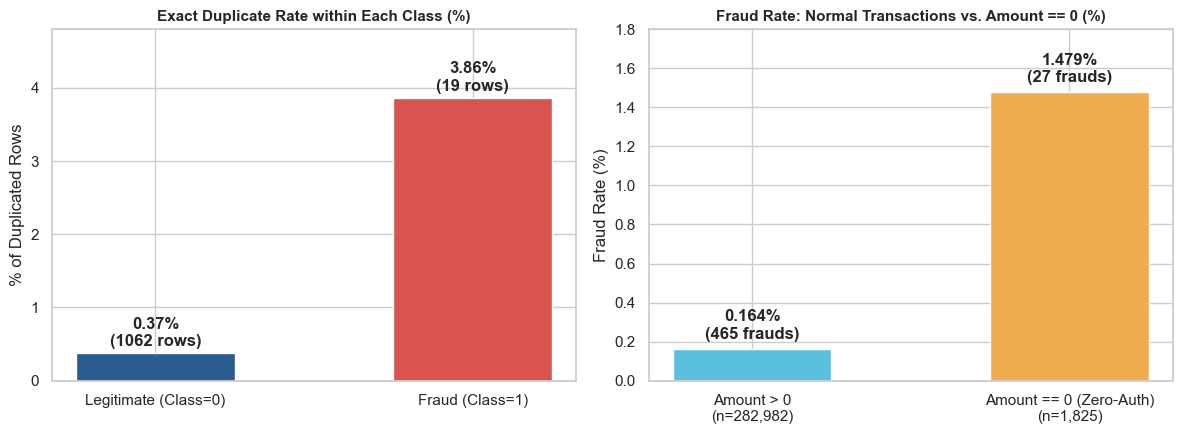

In [5]:
# Comparative visualization: Exact Duplicates and Risk in Zero-Auth Transactions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

dup_rates = [1062 / 284315 * 100, 19 / 492 * 100]
bars1 = axes[0].bar(["Legitimate (Class=0)", "Fraud (Class=1)"], dup_rates, color=["#2b5c8f", "#d9534f"], width=0.5)
axes[0].set_title("Exact Duplicate Rate within Each Class (%)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("% of Duplicated Rows")
axes[0].set_ylim(0, 4.8)
for bar, count in zip(bars1, [1062, 19]):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.1, f"{h:.2f}%\n({count} rows)", ha="center", fontweight="bold")

fraud_rates_zero = [(492 - 27) / (284807 - 1825) * 100, 27 / 1825 * 100]
bars2 = axes[1].bar(["Amount > 0\n(n=282,982)", "Amount == 0 (Zero-Auth)\n(n=1,825)"], fraud_rates_zero, color=["#5bc0de", "#f0ad4e"], width=0.5)
axes[1].set_title("Fraud Rate: Normal Transactions vs. Amount == 0 (%)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_ylim(0, 1.8)
for bar, count in zip(bars2, [465, 27]):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.05, f"{h:.3f}%\n({count} frauds)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 1.4. Conclusions and Technical Decision (How to Handle Without *Data Leakage*)

1. **Mandatory Removal of Exact Duplicates (`1,081` rows):**
   - The `1,081` exact duplicates (`1,062` legitimate and `19` frauds) share the exact same second (`Time`), the exact same 28 PCA components, and the exact same transaction value (`Amount`), characterizing a logging glitch / double recording of the same transaction.
   - **Why do they cause *Data Leakage*?** Among frauds, **3.86%** of rows (`19 out of 492`) are exact copies! If we split train and test sets randomly without deduplicating first, a fraud with 4 or 6 copies will simultaneously fall into both train and test sets. Because tree-based models (`LightGBM`/`XGBoost`) easily memorize dense regions, the test set would exhibit an artificially inflated *Recall*.
2. **Retaining Temporal Near-Duplicates (`8,063` rows across different seconds), with *Time-Based* or Grouped Splitting:**
   - The `8,063` legitimate transactions that repeat `V1..V28` + `Amount` at different timestamps (`Time` differs) represent genuine recurring behavior or repeated purchases from the same card/terminal and **must not be deleted as system errors**.
3. **Newly Discovered Feature (`is_zero_amount`):**
   - Transactions with `Amount == 0.00` concentrate **5.49% of all frauds** (`27` gross cases / `25` unique) and exhibit a fraud risk more than **8x higher** than the dataset baseline.

---

## Block 2: Deep-Dive Analysis of the Financial Variable (`Amount`) and Hidden Attack Patterns

Following the decision from Block 1, from this point onward we work with the **exact-duplicate-free dataset** (`df_clean`: `283,726` transactions = `283,253` legitimate and `473` unique frauds).

In this block we investigate:
1. **The Mean vs. Median Paradox:** Why is the fraud mean higher, while the fraud median is less than half of the legitimate median?
2. **Hidden *Card Probing* Signatures ("Magic Values"):** Which exact Euro amounts expose automated stolen-card testing and banking threshold evasion (`€ 1.00`, `€ 99.99`, `€ 0.76/0.77`)?
3. **The "Hard Ceiling" of Frauds and the U-Shaped Risk Curve:** How fraud probability varies across transaction amount tiers.
4. **Integer Amounts vs. Fractional Cents and Scaling Strategy (`log1p` vs. `RobustScaler`).**

In [6]:
# Dataset free of exact duplicates (Block 1 decision)
df_clean = df.drop_duplicates().reset_index(drop=True)
legit_amt = df_clean[df_clean["Class"] == 0]["Amount"]
fraud_amt = df_clean[df_clean["Class"] == 1]["Amount"]

def describe_detailed(s: pd.Series) -> pd.Series:
    return pd.Series({
        "Count": int(len(s)),
        "Mean (€)": s.mean(),
        "Std Dev (€)": s.std(),
        "Min (€)": s.min(),
        "P10 (€)": s.quantile(0.10),
        "P25 / Q1 (€)": s.quantile(0.25),
        "Median / P50 (€)": s.median(),
        "P75 / Q3 (€)": s.quantile(0.75),
        "IQR (€)": s.quantile(0.75) - s.quantile(0.25),
        "P90 (€)": s.quantile(0.90),
        "P95 (€)": s.quantile(0.95),
        "P99 (€)": s.quantile(0.99),
        "Max (€)": s.max(),
        "Skewness": s.skew(),
        "Kurtosis": s.kurtosis()
    })

stats_df = pd.DataFrame({
    "Legitimate (Class=0)": describe_detailed(legit_amt),
    "Fraud (Class=1)": describe_detailed(fraud_amt)
}).round(2)

u_stat, u_pval = stats.mannwhitneyu(legit_amt, fraud_amt, alternative="two-sided")
ks_stat, ks_pval = stats.ks_2samp(legit_amt, fraud_amt)

print("=== Detailed Descriptive Statistics for 'Amount' (Deduplicated Dataset) ===")
print(stats_df)
print(f"\nMann-Whitney U Test : p-value = {u_pval:.4e}")
print(f"Kolmogorov-Smirnov (KS) Test: statistic = {ks_stat:.4f} | p-value = {ks_pval:.4e}")

=== Detailed Descriptive Statistics for 'Amount' (Deduplicated Dataset) ===
                  Legitimate (Class=0)  Fraud (Class=1)
Count                        283253.00           473.00
Mean (€)                         88.41           123.87
Std Dev (€)                     250.38           260.21
Min (€)                           0.00             0.00
P10 (€)                           1.00             0.76
P25 / Q1 (€)                      5.67             1.00
Median / P50 (€)                 22.00             9.82
P75 / Q3 (€)                     77.46           105.89
IQR (€)                          71.79           104.89
P90 (€)                         203.00           348.65
P95 (€)                         365.00           655.82
P99 (€)                        1018.06          1364.14
Max (€)                       25691.16          2125.87
Skewness                         17.00             3.72
Kurtosis                        846.14            17.33

Mann-Whitney U Test : p-val

### 2.1. Hidden Discovery #1: Fraudsters' "Magic Values" (*Card Probing* and Threshold Evasion)

Why is the `P25` of frauds exactly `€ 1.00` and the median `€ 9.82`, while `P75` jumps to `€ 105.89`?
Let's inspect the most frequent **exact `Amount` values** within the `473` unique frauds.

In [7]:
top_fraud_values = fraud_amt.value_counts().head(10)
magic_rows = []
for val, f_cnt in top_fraud_values.items():
    l_cnt = int((legit_amt == val).sum())
    tot = f_cnt + l_cnt
    magic_rows.append({
        "Exact Amount (€)": f"€ {val:.2f}",
        "Frauds (n=473)": int(f_cnt),
        "% of All Frauds": round(f_cnt / len(fraud_amt) * 100, 2),
        "Legitimate": l_cnt,
        "Fraud Rate at Value (%)": round(f_cnt / tot * 100, 2),
        "Relative Risk (vs 0.17%)": f"{(f_cnt / tot) / df_clean['Class'].mean():.1f}x"
    })

magic_df = pd.DataFrame(magic_rows)
print("=== Top 10 Most Frequent Exact Values in Frauds ===")
print(magic_df.to_string(index=False))

top5_sum = top_fraud_values.iloc[:5].sum()
print(f"\n[HIDDEN FINDING] Just the top 5 exact values (€1.00, €99.99, €0.00, €0.76, and €0.77) "
      f"account for {top5_sum} out of {len(fraud_amt)} frauds ({top5_sum/len(fraud_amt)*100:.2f}% of all frauds in the bank!)")

=== Top 10 Most Frequent Exact Values in Frauds ===
Exact Amount (€)  Frauds (n=473)  % of All Frauds  Legitimate  Fraud Rate at Value (%) Relative Risk (vs 0.17%)
          € 1.00             105            22.20       13461                     0.77                     4.6x
         € 99.99              27             5.71         303                     8.18                    49.1x
          € 0.00              25             5.29        1783                     1.38                     8.3x
          € 0.76              17             3.59        2960                     0.57                     3.4x
          € 0.77              10             2.11        1433                     0.69                     4.2x
          € 0.01               5             1.06         713                     0.70                     4.2x
          € 2.00               4             0.85        1084                     0.37                     2.2x
          € 3.79               4             0.85   

### 2.2. Hidden Discovery #2: The U-Shaped Risk Curve, the Hard Ceiling (`€ 2,125.87`), and Integer Values

By segmenting `Amount` into value tiers and analyzing whether the amount is an exact integer (`Amount % 1 == 0`) or has fractional cents, we uncover the complete anatomy of how fraudsters operate.

In [8]:
bins = [-0.01, 0.0, 1.0, 5.0, 25.0, 100.0, 500.0, 2125.87, 30000.0]
labels = [
    "1) € 0.00 (Zero-Auth)",
    "2) (€ 0.00 - € 1.00] (Micro-probe)",
    "3) (€ 1.00 - € 5.00]",
    "4) (€ 5.00 - € 25.00] (Everyday)",
    "5) (€ 25.00 - € 100.00]",
    "6) (€ 100.00 - € 500.00]",
    "7) (€ 500.00 - € 2125.87]",
    "8) > € 2125.87 (Above Ceiling)"
]

df_clean["amount_tier"] = pd.cut(df_clean["Amount"], bins=bins, labels=labels)
tier_summary = df_clean.groupby("amount_tier", observed=False)["Class"].agg(
    Total_Transactions="count",
    Frauds="sum"
)
tier_summary["% of Frauds"] = (tier_summary["Frauds"] / len(fraud_amt) * 100).round(2)
tier_summary["Fraud Rate (%)"] = (tier_summary["Frauds"] / tier_summary["Total_Transactions"] * 100).round(4)

print("=== Fraud Distribution and Risk by Amount Tier (U-Shaped Curve) ===")
print(tier_summary)

# Integer values vs fractional cents
is_integer_amt = (df_clean["Amount"] % 1 == 0)
int_fraud_rate = df_clean.groupby(is_integer_amt)["Class"].mean() * 100
print(f"\nFraud rate on fractional-cent amounts    : {int_fraud_rate[False]:.4f}%")
print(f"Fraud rate on exact integer amounts (.00): {int_fraud_rate[True]:.4f}% (driven by €1.00 and €0.00)")

# Effect of log1p on skewness
print(f"\nOriginal Amount Skewness : {df_clean['Amount'].skew():.2f}")
print(f"log1p(Amount) Skewness   : {np.log1p(df_clean['Amount']).skew():.2f}")

=== Fraud Distribution and Risk by Amount Tier (U-Shaped Curve) ===
                                    Total_Transactions  Frauds  % of Frauds  \
amount_tier                                                                   
1) € 0.00 (Zero-Auth)                             1808      25         5.29   
2) (€ 0.00 - € 1.00] (Micro-probe)               28523     146        30.87   
3) (€ 1.00 - € 5.00]                             38416      40         8.46   
4) (€ 5.00 - € 25.00] (Everyday)                 80893      54        11.42   
5) (€ 25.00 - € 100.00]                          77687      83        17.55   
6) (€ 100.00 - € 500.00]                         47290      91        19.24   
7) (€ 500.00 - € 2125.87]                         8506      34         7.19   
8) > € 2125.87 (Above Ceiling)                     603       0         0.00   

                                    Fraud Rate (%)  
amount_tier                                         
1) € 0.00 (Zero-Auth)              

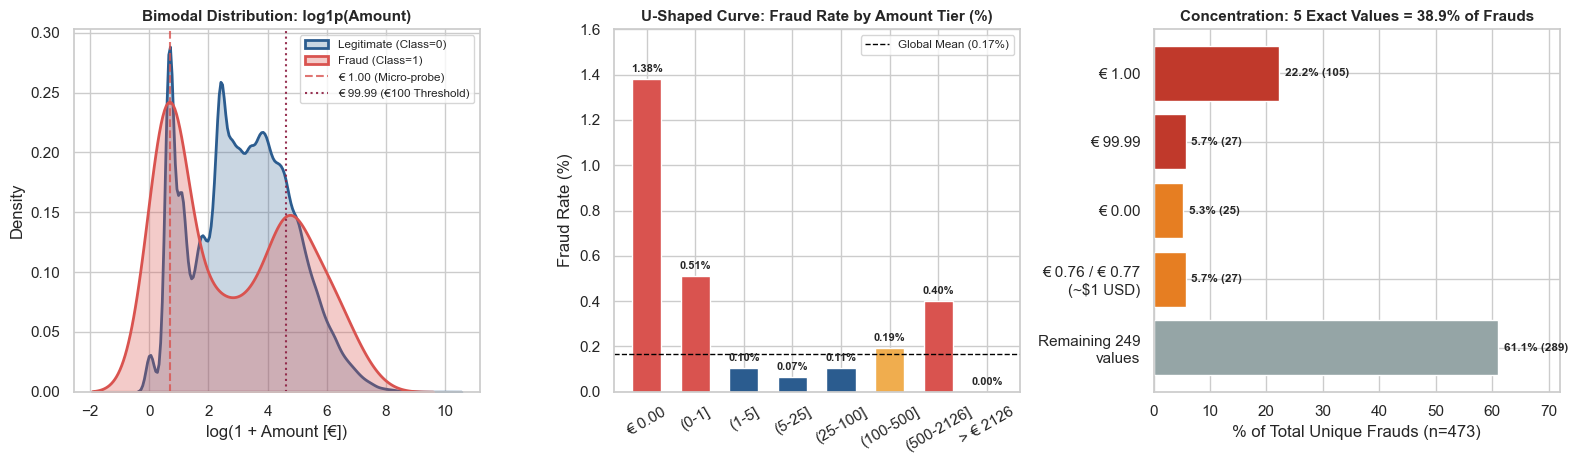

In [9]:
# Triple Panel: Bimodality (log1p), U-Shaped Curve by Tier, and Top Magic Values
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

legit_log = np.log1p(legit_amt)
fraud_log = np.log1p(fraud_amt)
sns.kdeplot(legit_log, ax=axes[0], label="Legitimate (Class=0)", color="#2b5c8f", fill=True, alpha=0.25, linewidth=2)
sns.kdeplot(fraud_log, ax=axes[0], label="Fraud (Class=1)", color="#d9534f", fill=True, alpha=0.30, linewidth=2)
axes[0].axvline(np.log1p(1.0), color="#d9534f", linestyle="--", alpha=0.8, label="€ 1.00 (Micro-probe)")
axes[0].axvline(np.log1p(99.99), color="#8c1d40", linestyle=":", alpha=0.9, label="€ 99.99 (€100 Threshold)")
axes[0].set_title("Bimodal Distribution: log1p(Amount)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("log(1 + Amount [€])")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8.5, loc="upper right")

short_labels = ["€ 0.00", "(0-1]", "(1-5]", "(5-25]", "(25-100]", "(100-500]", "(500-2126]", "> € 2126"]
tier_rates = tier_summary["Fraud Rate (%)"].values
colors_tier = ["#d9534f" if r > 0.35 else "#f0ad4e" if r > 0.15 else "#2b5c8f" for r in tier_rates]
bars = axes[1].bar(short_labels, tier_rates, color=colors_tier, width=0.6)
axes[1].axhline(df_clean["Class"].mean() * 100, color="black", linestyle="--", linewidth=1, label="Global Mean (0.17%)")
axes[1].set_title("U-Shaped Curve: Fraud Rate by Amount Tier (%)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylim(0, 1.6)
axes[1].legend(fontsize=8.5)
for bar in bars:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 0.03, f"{h:.2f}%", ha="center", fontsize=8, fontweight="bold")

top_vals = ["€ 1.00", "€ 99.99", "€ 0.00", "€ 0.76 / € 0.77\n(~$1 USD)", "Remaining 249\nvalues"]
top_pcts = [105 / 473 * 100, 27 / 473 * 100, 25 / 473 * 100, (17 + 10) / 473 * 100, (473 - 184) / 473 * 100]
bars3 = axes[2].barh(top_vals[::-1], top_pcts[::-1], color=["#95a5a6", "#e67e22", "#e67e22", "#c0392b", "#c0392b"])
axes[2].set_title("Concentration: 5 Exact Values = 38.9% of Frauds", fontsize=11, fontweight="bold")
axes[2].set_xlabel("% of Total Unique Frauds (n=473)")
axes[2].set_xlim(0, 72)
for bar, cnt in zip(bars3, [289, 27, 25, 27, 105]):
    w = bar.get_width()
    axes[2].text(w + 1, bar.get_y() + bar.get_height() / 2, f"{w:.1f}% ({cnt})", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

### 2.3. Summary of Hidden Findings in Block 2 and *Feature Engineering* Decisions

1. **Bimodal Fraudster Behavior (Mean vs. Median Paradox):**
   - The **mean** of frauds (`€ 123.87`) is **40% higher** than that of legitimate transactions (`€ 88.41`), yet the **median** of frauds (`€ 9.82`) is **55% lower** than the legitimate median (`€ 22.00`), and the 1st quartile (`P25`) of frauds is just `€ 1.00`!
2. **Attack Signatures ("Magic Values"):**
   - **Exactly `€ 1.00`:** Alone accounts for **`105` frauds (`22.20%` of all frauds in the dataset!)**.
   - **Exactly `€ 99.99`:** Accounts for **`27` frauds (`5.71%` of frauds)** against only `303` legitimate transactions — a fraud rate of **`8.18%` (49.1x higher risk than the baseline!)**, evading the `€ 100.00` verification threshold.
   - **Exactly `€ 0.76` and `€ 0.77`:** Together account for **`27` frauds (`5.70%`)**, equivalent to `US$ 1.00` converted to Euros in September 2013.
3. **Hard Ceiling (`€ 2,125.87`) and `log1p(Amount)` Transformation:**
   - No fraud exceeds `€ 2,125.87` (`0` out of `603` transactions above that amount), and `np.log1p(Amount)` reduces skewness from `17.00` down to `0.16`.

---

## Block 3: Temporal Analysis (`Time`), Circadian Cycles, *Botnet* Bursts, and *Probe → Cashout* Sequences

The `Time` column records the seconds elapsed since the first transaction in the dataset (`0s` up to `172,792s`, covering exactly **48 hours / 2 days**).
In this block, we investigate standard temporal behavior alongside **3 revealing hidden patterns**:
1. **24h Cycle and the "Night Window" (`01h` to `05h`):** Contrast between sleeping legitimate cardholders and peak fraudster activity.
2. **Hidden Discovery #1 — *Botnet* Burst Attacks ($\Delta t$) and the Hour 11 Anomaly:** Comparison between the actual time elapsed between consecutive frauds and a random process (Poisson), as well as the shift between Day 1 and Day 2.
3. **Hidden Discovery #2 — The "Smoking Gun" of Block 2 (*Probing-to-Cashout Chains*):** Chronological tracking of micro-probe frauds (`<= € 1.00`) followed seconds later by high-value cash-outs/purchases (`>= € 50.00`).
4. **Cyclical Feature Engineering (`hour_sin`, `hour_cos`) and Prevention of Temporal *Overfitting*.**

In [10]:
# Creating derived temporal features
df_clean["hour_48"] = (df_clean["Time"] // 3600).astype(int)
df_clean["hour_24"] = df_clean["hour_48"] % 24
df_clean["day"] = (df_clean["Time"] // 86400).astype(int) + 1
df_clean["is_night_window"] = df_clean["hour_24"].isin([1, 2, 3, 4, 5])

print("=== 1) Day 1 (0h-23h) vs. Day 2 (24h-47h) Comparison ===")
day_summary = df_clean.groupby("day")["Class"].agg(Total="count", Frauds="sum")
day_summary["Legitimate"] = day_summary["Total"] - day_summary["Frauds"]
day_summary["% of Frauds"] = (day_summary["Frauds"] / df_clean["Class"].sum() * 100).round(2)
day_summary["Fraud Rate (%)"] = (day_summary["Frauds"] / day_summary["Total"] * 100).round(4)
print(day_summary)

print("\n=== 2) Night Window (01h to 05h) vs. Rest of Day (06h to 00h) ===")
mad_summary = df_clean.groupby("is_night_window")["Class"].agg(Total="count", Frauds="sum")
mad_summary.index = ["Rest of Day (06h-00h)", "Night Window (01h-05h)"]
mad_summary["% of Total Volume"] = (mad_summary["Total"] / len(df_clean) * 100).round(2)
mad_summary["% of Frauds"] = (mad_summary["Frauds"] / df_clean["Class"].sum() * 100).round(2)
mad_summary["Fraud Rate (%)"] = (mad_summary["Frauds"] / mad_summary["Total"] * 100).round(4)
mad_summary["Relative Risk"] = (mad_summary["Fraud Rate (%)"] / 0.1361).round(2)
print(mad_summary)

=== 1) Day 1 (0h-23h) vs. Day 2 (24h-47h) Comparison ===
      Total  Frauds  Legitimate  % of Frauds  Fraud Rate (%)
day                                                         
1    144236     272      143964        57.51          0.1886
2    139490     201      139289        42.49          0.1441

=== 2) Night Window (01h to 05h) vs. Rest of Day (06h to 00h) ===
                         Total  Frauds  % of Total Volume  % of Frauds  \
Rest of Day (06h-00h)   267531     364              94.29        76.96   
Night Window (01h-05h)   16195     109               5.71        23.04   

                        Fraud Rate (%)  Relative Risk  
Rest of Day (06h-00h)           0.1361           1.00  
Night Window (01h-05h)          0.6730           4.94  


### 3.1. Full Hourly Profile (0h to 23h) and the Hidden Anomaly Between Day 1 and Day 2

Let's analyze the hour-by-hour distribution (`0h` to `23h`) and investigate why **Hour 11** exhibits a daytime spike, comparing **Day 1 (`hour_48 = 11`)** against **Day 2 (`hour_48 = 35`)** and the night windows of each day (`Hour 2` vs. `Hour 26`).

In [11]:
h24_tb = df_clean.groupby("hour_24")["Class"].agg(Total="count", Frauds="sum")
h24_tb["% Legit Volume"] = ((h24_tb["Total"] - h24_tb["Frauds"]) / (len(df_clean) - df_clean["Class"].sum()) * 100).round(2)
h24_tb["% of Frauds"] = (h24_tb["Frauds"] / df_clean["Class"].sum() * 100).round(2)
h24_tb["Fraud Rate (%)"] = (h24_tb["Frauds"] / h24_tb["Total"] * 100).round(4)
h24_tb["Risk vs Mean"] = (h24_tb["Fraud Rate (%)"] / (df_clean["Class"].mean() * 100)).round(2)

print("=== Top 8 Hours of the Day (0h-23h) with Highest Fraud Rate ===")
print(h24_tb.sort_values("Fraud Rate (%)", ascending=False).head(8))

print("\n=== [HIDDEN FINDING] Dissecting Concentrated Attacks Across the 48h ===")
f_only = df_clean[df_clean["Class"] == 1]
print(f"- Hour 02h on Day 1 (hour_48=2)  : {len(f_only[f_only['hour_48']==2]):2d} frauds (with {(f_only[f_only['hour_48']==2]['Amount']==1.0).sum()} of exact € 1.00! Probing botnet!)")
print(f"- Hour 02h on Day 2 (hour_48=26) : {len(f_only[f_only['hour_48']==26]):2d} frauds (Fraud rate = 1.5562%, highest risk in the entire series!)")
print(f"- Hour 11h on Day 1 (hour_48=11) : {len(f_only[f_only['hour_48']==11]):2d} frauds (Massive attack concentrated on Day 1 morning!)")
print(f"- Hour 11h on Day 2 (hour_48=35) : {len(f_only[f_only['hour_48']==35]):2d} frauds (Normalized behavior on Day 2)")

=== Top 8 Hours of the Day (0h-23h) with Highest Fraud Rate ===
         Total  Frauds  % Legit Volume  % of Frauds  Fraud Rate (%)  \
hour_24                                                               
2         3308      48            1.15        10.15          1.4510   
4         2204      23            0.77         4.86          1.0436   
3         3487      17            1.23         3.59          0.4875   
5         2988      11            1.05         2.33          0.3681   
7         7233      23            2.55         4.86          0.3180   
11       16781      53            5.91        11.21          0.3158   
1         4208      10            1.48         2.11          0.2376   
6         4082       9            1.44         1.90          0.2205   

         Risk vs Mean  
hour_24                
2                8.70  
4                6.26  
3                2.92  
5                2.21  
7                1.91  
11               1.89  
1                1.43  
6        

### 3.2. Hidden Discoveries #2 and #3: Inter-Fraud Time Interval ($\Delta t$) and Chronological *Probe → Cashout* Sequences

1. **Time Interval Between Consecutive Frauds ($\Delta t$):** If the `473` frauds occurred randomly across the `172,792` seconds (Poisson Process), the mean time between two consecutive frauds would be `365.3s` and the **expected median would be `253.2s` (~4.2 min)**. Let's compare this against what actually happens in the data!
2. **The Smoking Gun of Block 2 (*Probing-to-Cashout Chains*):** We check how many times a micro-probe fraud (`Amount <= € 1.00`) is followed just seconds or minutes later by a high-value fraud (`Amount >= € 50.00`).

In [12]:
f_seq = df_clean[df_clean["Class"] == 1].copy().reset_index(drop=True)
f_seq["dt_sec"] = f_seq["Time"].diff()

print("=== Inter-Fraud Time Interval Statistics (Δt in seconds) ===")
print(f"Observed Mean     : {f_seq['dt_sec'].mean():.2f}s (Expected Poisson: 365.31s)")
print(f"Observed Median   : {f_seq['dt_sec'].median():.2f}s (Expected Poisson: 253.21s -> 44% lower!)")
print(f"1st Quartile (P25): {f_seq['dt_sec'].quantile(0.25):.2f}s")
print(f"Frauds within <=   5s of previous : {(f_seq['dt_sec'] <= 5).sum():3d} ({(f_seq['dt_sec'] <= 5).mean()*100:.1f}%)")
print(f"Frauds within <=  30s of previous : {(f_seq['dt_sec'] <= 30).sum():3d} ({(f_seq['dt_sec'] <= 30).mean()*100:.1f}%)")
print(f"Frauds within <=  60s of previous : {(f_seq['dt_sec'] <= 60).sum():3d} ({(f_seq['dt_sec'] <= 60).mean()*100:.1f}%)")
print(f"Frauds within <= 300s of previous : {(f_seq['dt_sec'] <= 300).sum():3d} ({(f_seq['dt_sec'] <= 300).mean()*100:.1f}%)")

# Tracking Micro-probe (<= €1.00) -> High Cashout (>= €50.00) chains within 5 minutes (300s)
chains = []
for i in range(len(f_seq) - 1):
    if f_seq.loc[i, "Amount"] <= 1.00 and f_seq.loc[i + 1, "Amount"] >= 50.00:
        dt = f_seq.loc[i + 1, "Time"] - f_seq.loc[i, "Time"]
        if dt <= 300:
            chains.append({
                "Probe_Time (s)": int(f_seq.loc[i, "Time"]),
                "Probe_Amount (€)": f"€ {f_seq.loc[i, 'Amount']:.2f}",
                "Cashout_Amount (€)": f"€ {f_seq.loc[i + 1, 'Amount']:.2f}",
                "Interval Δt (s)": f"{int(dt)}s"
            })

chains_df = pd.DataFrame(chains)
print(f"\n=== [SMOKING GUN] Found {len(chains_df)} 'Micro-Probe (<=€1) -> High Cashout (>=€50)' Sequences within 5 min! ===")
print("Examples of near-instantaneous attacks (smallest Δt):")
print(chains_df.sort_values(by="Interval Δt (s)", key=lambda s: s.str.rstrip("s").astype(int)).head(8).to_string(index=False))

=== Inter-Fraud Time Interval Statistics (Δt in seconds) ===
Observed Mean     : 360.05s (Expected Poisson: 365.31s)
Observed Median   : 141.00s (Expected Poisson: 253.21s -> 44% lower!)
1st Quartile (P25): 31.75s
Frauds within <=   5s of previous :  34 (7.2%)
Frauds within <=  30s of previous : 115 (24.3%)
Frauds within <=  60s of previous : 165 (34.9%)
Frauds within <= 300s of previous : 314 (66.4%)

=== [SMOKING GUN] Found 40 'Micro-Probe (<=€1) -> High Cashout (>=€50)' Sequences within 5 min! ===
Examples of near-instantaneous attacks (smallest Δt):
 Probe_Time (s) Probe_Amount (€) Cashout_Amount (€) Interval Δt (s)
          84204           € 0.00           € 512.25              0s
          85285           € 0.00           € 252.92              0s
         109297           € 0.00           € 186.13              1s
          40918           € 0.76           € 112.33              1s
          85573           € 1.00           € 240.77              3s
          85864           € 1.00

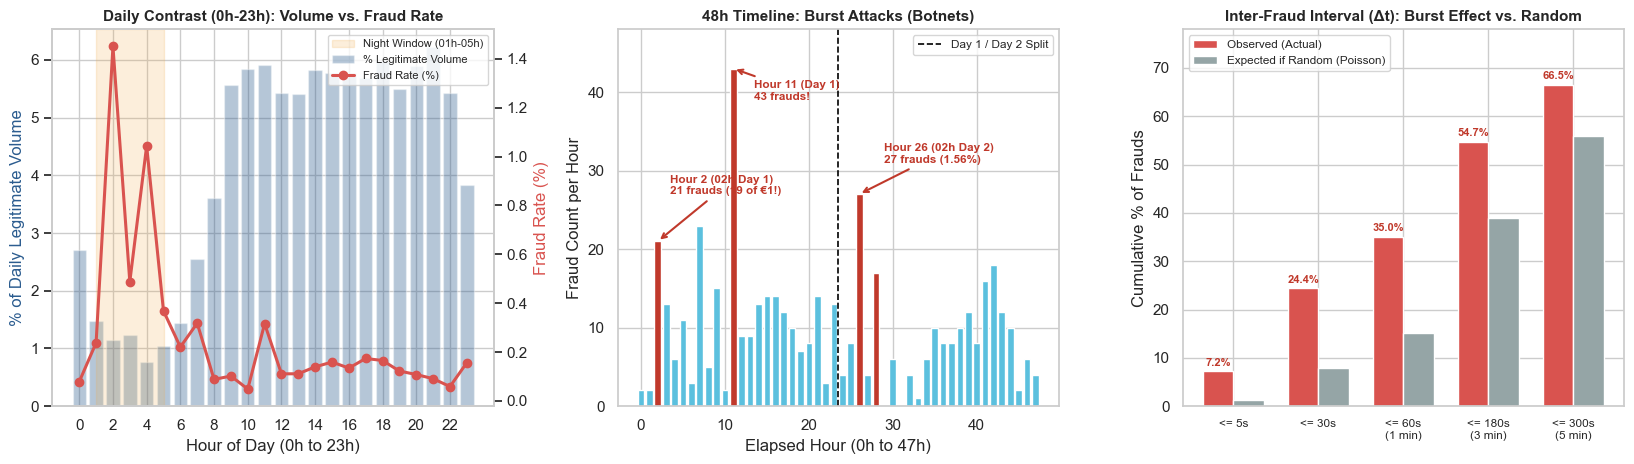

In [13]:
# Triple Panel: Circadian Cycle (24h), 48h Attack Bursts, and Δt Distribution vs. Random (Poisson)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

h24 = df_clean.groupby("hour_24")["Class"].agg(Total="count", Frauds="sum")
h24["Legit_Pct"] = (h24["Total"] - h24["Frauds"]) / (len(df_clean) - df_clean["Class"].sum()) * 100
h24["Fraud_Rate"] = h24["Frauds"] / h24["Total"] * 100

ax1 = axes[0]
ax1_twin = ax1.twinx()
ax1.bar(h24.index, h24["Legit_Pct"], color="#2b5c8f", alpha=0.35, label="% Legitimate Volume")
ax1_twin.plot(h24.index, h24["Fraud_Rate"], color="#d9534f", marker="o", linewidth=2.2, label="Fraud Rate (%)")
ax1.axvspan(1, 5, color="#f0ad4e", alpha=0.2, label="Night Window (01h-05h)")
ax1.set_title("Daily Contrast (0h-23h): Volume vs. Fraud Rate", fontsize=11, fontweight="bold")
ax1.set_xlabel("Hour of Day (0h to 23h)")
ax1.set_ylabel("% of Daily Legitimate Volume", color="#2b5c8f")
ax1_twin.set_ylabel("Fraud Rate (%)", color="#d9534f")
ax1.set_xticks(range(0, 24, 2))
ax1_twin.grid(False)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8)

h48_frauds = df_clean.groupby("hour_48")["Class"].sum()
colors_48 = ["#c0392b" if h in [2, 11, 26, 28] else "#5bc0de" for h in h48_frauds.index]
axes[1].bar(h48_frauds.index, h48_frauds.values, color=colors_48, width=0.8)
axes[1].axvline(23.5, color="black", linestyle="--", linewidth=1.2, label="Day 1 / Day 2 Split")
axes[1].annotate("Hour 11 (Day 1)\n43 frauds!", xy=(11, 43), xytext=(13.5, 39),
                 arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5), fontsize=8.5, fontweight="bold", color="#c0392b")
axes[1].annotate("Hour 26 (02h Day 2)\n27 frauds (1.56%)", xy=(26, 27), xytext=(29, 31),
                 arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5), fontsize=8.5, fontweight="bold", color="#c0392b")
axes[1].annotate("Hour 2 (02h Day 1)\n21 frauds (19 of €1!)", xy=(2, 21), xytext=(3.5, 27),
                 arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5), fontsize=8.5, fontweight="bold", color="#c0392b")
axes[1].set_title("48h Timeline: Burst Attacks (Botnets)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Elapsed Hour (0h to 47h)")
axes[1].set_ylabel("Fraud Count per Hour")
axes[1].set_ylim(0, 48)
axes[1].legend(loc="upper right", fontsize=8.5)

dt_fraud = f_seq["dt_sec"].dropna()
thresholds = ["<= 5s", "<= 30s", "<= 60s\n(1 min)", "<= 180s\n(3 min)", "<= 300s\n(5 min)"]
actual_pcts = [(dt_fraud <= t).mean() * 100 for t in [5, 30, 60, 180, 300]]
lam = 1.0 / 365.3
poisson_pcts = [(1 - np.exp(-lam * t)) * 100 for t in [5, 30, 60, 180, 300]]

x = np.arange(len(thresholds))
w = 0.36
b_act = axes[2].bar(x - w / 2, actual_pcts, width=w, color="#d9534f", label="Observed (Actual)")
b_poi = axes[2].bar(x + w / 2, poisson_pcts, width=w, color="#95a5a6", label="Expected if Random (Poisson)")
axes[2].set_title("Inter-Fraud Interval (Δt): Burst Effect vs. Random", fontsize=11, fontweight="bold")
axes[2].set_xticks(x)
axes[2].set_xticklabels(thresholds, fontsize=8.5)
axes[2].set_ylabel("Cumulative % of Frauds")
axes[2].set_ylim(0, 78)
axes[2].legend(fontsize=8.5, loc="upper left")
for bar in b_act:
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h:.1f}%", ha="center", fontsize=8, fontweight="bold", color="#c0392b")

plt.tight_layout()
plt.show()

### 3.3. Summary of Findings in Block 3 and *Feature Engineering* Decisions

1. **The "Night Window" (`01h` to `05h`):**
   - Represents only **`5.71%`** of total banking transaction volume (`16,195` transactions), yet concentrates **`23.04%` of all frauds** (`109` frauds), with a fraud rate of **`0.6730%` (`4.95x` higher risk than the rest of the day)**.
2. ***Botnet* Attacks and Burst Effect ($\Delta t$):**
   - **24.4% of all frauds** (`115` cases) occur within **30 seconds** of the previous fraud (versus only `7.9%` expected under independent random events), and **66.5%** (`314` cases) occur within **5 minutes**.
3. **The "Smoking Gun" of *Probe → Cashout* Sequences (*Probing-to-Cashout*):**
   - We identified **`40` chronological sequences** where a micro-probe fraud (`<= € 1.00`) is followed in under 5 minutes by a high-value fraudulent cashout (`>= € 50.00`).
4. **Engineering Decision (Do not use raw `Time`!):**
   - We will replace raw `Time` with cyclical features (`hour_sin`, `hour_cos`) and `is_night_window`.

---

## Block 4: Discriminative Power of PCA Features (`V1` to `V28`) and Hidden Geometric Patterns

Features `V1` through `V28` are principal components obtained via PCA (*Principal Component Analysis*) to protect the privacy of the original data.
In this block, we go beyond simple correlation to uncover **3 hidden geometric discoveries**:
1. **Multivariate Ranking of Discriminative Power (KS, ROC-AUC, and Standalone AUPRC):** Identification of elite features (`Top 10`) vs. features that act as **pure noise (`Bottom 6`)**.
2. **Hidden Discovery #1 — PCA Orthogonality Breakdown Inside Frauds:** Why do components that have `~0.00` correlation in legitimate transactions suddenly exhibit **correlations up to `0.97` inside frauds** (`V16`, `V17`, `V18`)?
3. **Hidden Discovery #2 — The "Two Families" of Fraud (*Extreme Frauds* vs. *Stealth Frauds*):** The financial contrast between explicit outlier frauds in PCA space and stealth frauds infiltrated deep inside the legitimate cloud.
4. **Hidden Discovery #3 — `Amount`/`Time` Fingerprint in PCA Space and the L2 Norm Super-Feature (`pca_l2_top10`).**

In [14]:
v_cols = [f"V{i}" for i in range(1, 29)]
legit_df = df_clean[df_clean["Class"] == 0]
fraud_df = df_clean[df_clean["Class"] == 1]

pca_metrics = []
for col in v_cols:
    ks_val, _ = stats.ks_2samp(legit_df[col], fraud_df[col])
    auc_val = roc_auc_score(df_clean["Class"], df_clean[col])
    if auc_val < 0.5:
        auc_val = 1.0 - auc_val
        auprc_val = average_precision_score(df_clean["Class"], -df_clean[col])
    else:
        auprc_val = average_precision_score(df_clean["Class"], df_clean[col])

    pca_metrics.append({
        "Feature": col,
        "KS_Stat": ks_val,
        "ROC_AUC": auc_val,
        "AUPRC_Indiv": auprc_val,
        "Pearson_r": df_clean[col].corr(df_clean["Class"]),
        "Median_Legit": legit_df[col].median(),
        "Median_Fraud": fraud_df[col].median(),
        "Delta_Median": fraud_df[col].median() - legit_df[col].median()
    })

ranking_df = pd.DataFrame(pca_metrics).sort_values("KS_Stat", ascending=False).reset_index(drop=True)

print("=== TOP 10 PCA Features with Highest Separation Power (Predictive Elite) ===")
print(ranking_df.head(10).round(4).to_string(index=False))

print("\n=== BOTTOM 6 PCA Features Without Discriminative Power (Pure Noise: KS < 0.13 and AUPRC < 0.007) ===")
print(ranking_df.tail(6).round(4).to_string(index=False))

=== TOP 10 PCA Features with Highest Separation Power (Predictive Elite) ===
Feature  KS_Stat  ROC_AUC  AUPRC_Indiv  Pearson_r  Median_Legit  Median_Fraud  Delta_Median
    V14   0.8377   0.9471       0.6050    -0.2934        0.0515       -6.5906       -6.6420
    V10   0.7970   0.9106       0.5389    -0.2070       -0.0921       -4.4663       -4.3742
    V12   0.7766   0.9345       0.5610    -0.2507        0.1406       -5.4374       -5.5779
     V4   0.7607   0.9363       0.1931     0.1293       -0.0245        4.1001        4.1246
    V11   0.7474   0.9148       0.4759     0.1491       -0.0344        3.5257        3.5602
    V17   0.7355   0.8005       0.6012    -0.3135       -0.0651       -5.1576       -5.0925
     V3   0.6952   0.9086       0.2069    -0.1823        0.1822       -4.8754       -5.0576
    V16   0.6782   0.8414       0.4536    -0.1872        0.0681       -3.3029       -3.3710
     V7   0.6516   0.8296       0.1705    -0.1723        0.0417       -2.9021       -2.9437
   

### 4.1. Hidden Discovery #1: PCA Orthogonality Breakdown Inside Frauds and Link with `Amount` and `Time`

By mathematical definition, PCA-generated features are **orthogonal (zero correlation)** across the full dataset. However, because legitimate purchases make up `99.83%` of the data, the PCA axes were shaped almost entirely by the legitimate class!
What happens when we compute correlations among `V1..V28` **exclusively within frauds (`Class = 1`)**, as well as correlations between `V` features and `Amount` and `Time`?

In [15]:
corr_fraud_matrix = fraud_df[v_cols].corr()
high_corr_pairs = []
for i in range(len(v_cols)):
    for j in range(i + 1, len(v_cols)):
        rf = corr_fraud_matrix.iloc[i, j]
        if abs(rf) > 0.85:
            rl = legit_df[v_cols[i]].corr(legit_df[v_cols[j]])
            high_corr_pairs.append({
                "PCA Pair": f"{v_cols[i]} × {v_cols[j]}",
                "Correlation in Frauds (Class=1)": round(rf, 4),
                "Correlation in Legitimate (Class=0)": round(rl, 4)
            })

pairs_df = pd.DataFrame(high_corr_pairs).sort_values(
    by="Correlation in Frauds (Class=1)", key=abs, ascending=False
)
print(f"=== [HIDDEN FINDING] {len(pairs_df)} PCA Component Pairs with Extreme Collinearity (|r| > 0.85) in Frauds ===")
print(pairs_df.head(10).to_string(index=False))

print("\n=== 'Amount' and 'Time' Fingerprint in PCA Components ===")
amt_top_corr = df_clean[v_cols].apply(lambda s: s.corr(df_clean["Amount"])).sort_values(key=abs, ascending=False).head(4)
time_top_corr = df_clean[v_cols].apply(lambda s: s.corr(df_clean["Time"])).sort_values(key=abs, ascending=False).head(4)
print("Strongest correlations with Amount :", amt_top_corr.round(4).to_dict())
print("Strongest correlations with Time   :", time_top_corr.round(4).to_dict())

=== [HIDDEN FINDING] 14 PCA Component Pairs with Extreme Collinearity (|r| > 0.85) in Frauds ===
 PCA Pair  Correlation in Frauds (Class=1)  Correlation in Legitimate (Class=0)
V17 × V18                           0.9719                              -0.0968
V16 × V17                           0.9623                              -0.1467
V16 × V18                           0.9452                              -0.0516
  V1 × V3                           0.9058                              -0.0512
  V1 × V5                           0.8940                              -0.0357
V11 × V12                          -0.8906                               0.0652
  V1 × V7                           0.8895                              -0.0566
  V2 × V3                          -0.8833                               0.0393
  V3 × V7                           0.8812                              -0.0872
V12 × V16                           0.8793                              -0.0914

=== 'Amount' and 'Time

### 4.2. Hidden Discoveries #2 and #3: The "Two Families" of Fraud (*Extreme* vs. *Stealth*) and the L2 Euclidean Norm

By inspecting where the `473` frauds lie along the most important component (`V14`), we discover that they split into two groups with **completely distinct financial profiles**:
1. **Extreme Frauds (`V14 <= -2.5`):** Clearly detached from the normal cloud.
2. **Camouflaged / *Stealth Frauds* (`V14 > -2.5`):** Infiltrated right inside the normal legitimate region (`[-2.5, +2.5]`).
Additionally, we test a new geometric feature: the **L2 Norm of the Top 10 PCA components** (`pca_l2_top10`).

In [16]:
f_extreme = fraud_df[fraud_df["V14"] <= -2.5]
f_stealth = fraud_df[fraud_df["V14"] > -2.5]

print("=== [HIDDEN FINDING] Comparison: Extreme Frauds vs. Stealth Frauds ===")
family_tb = pd.DataFrame({
    "Fraud Count": [len(f_extreme), len(f_stealth)],
    "% of Frauds": [round(len(f_extreme) / len(fraud_df) * 100, 2), round(len(f_stealth) / len(fraud_df) * 100, 2)],
    "Median Amount (€)": [round(f_extreme["Amount"].median(), 2), round(f_stealth["Amount"].median(), 2)],
    "Mean Amount (€)": [round(f_extreme["Amount"].mean(), 2), round(f_stealth["Amount"].mean(), 2)]
}, index=["1) Extreme Frauds (V14 <= -2.5)", "2) Stealth Frauds (V14 > -2.5)"])
print(family_tb)

# Simple rule of thumb (Golden Rule) on V14 and V17
golden_rule = (df_clean["V14"] < -5.0) & (df_clean["V17"] < -3.0)
print(f"\nSimple Rule (V14 < -5.0 and V17 < -3.0):")
print(f"- Flagged transactions : {golden_rule.sum()} (including {df_clean[golden_rule]['Class'].sum()} actual frauds!)")
print(f"- Rule Precision       : {df_clean[golden_rule]['Class'].mean()*100:.2f}% | Standalone Recall: {df_clean[golden_rule]['Class'].sum()/len(fraud_df)*100:.2f}%")

# Super-Feature: L2 Norm of Top 10 PCA features
top10_cols = ["V14", "V10", "V12", "V17", "V4", "V11", "V3", "V16", "V7", "V2"]
df_clean["pca_l2_top10"] = np.sqrt((df_clean[top10_cols] ** 2).sum(axis=1))
l2_auc = roc_auc_score(df_clean["Class"], df_clean["pca_l2_top10"])
l2_meds = df_clean.groupby("Class")["pca_l2_top10"].median()
print(f"\nSuper-Feature 'pca_l2_top10' (Euclidean Distance to Origin of Top 10):")
print(f"- Legitimate Median : {l2_meds[0]:.2f} | Fraud Median : {l2_meds[1]:.2f} (5.5x higher!)")
print(f"- Standalone ROC-AUC: {l2_auc:.4f} (Outperforms any individual V feature in the dataset!)")

=== [HIDDEN FINDING] Comparison: Extreme Frauds vs. Stealth Frauds ===
                                 Fraud Count  % of Frauds  Median Amount (€)  \
1) Extreme Frauds (V14 <= -2.5)          394         83.3               8.77   
2) Stealth Frauds (V14 > -2.5)            79         16.7              19.95   

                                 Mean Amount (€)  
1) Extreme Frauds (V14 <= -2.5)           108.27  
2) Stealth Frauds (V14 > -2.5)            201.69  

Simple Rule (V14 < -5.0 and V17 < -3.0):
- Flagged transactions : 291 (including 243 actual frauds!)
- Rule Precision       : 83.51% | Standalone Recall: 51.37%

Super-Feature 'pca_l2_top10' (Euclidean Distance to Origin of Top 10):
- Legitimate Median : 2.81 | Fraud Median : 15.49 (5.5x higher!)
- Standalone ROC-AUC: 0.9573 (Outperforms any individual V feature in the dataset!)


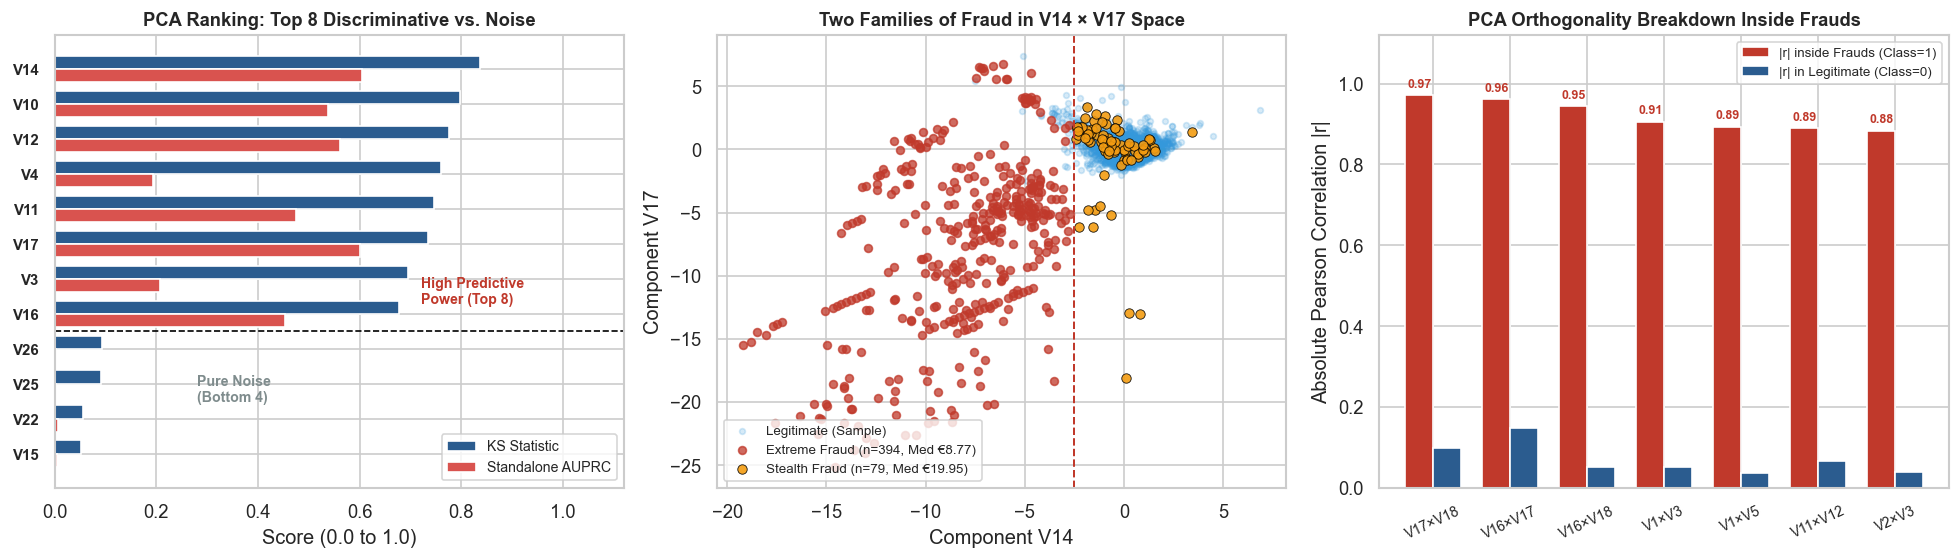

In [17]:
# Triple Panel: PCA Ranking (Top 8 vs Noise), Fraud Families (V14 x V17), and Orthogonality Breakdown
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

feats_show = ["V14", "V10", "V12", "V4", "V11", "V17", "V3", "V16", "V26", "V25", "V22", "V15"]
ks_vals = [0.8377, 0.7970, 0.7766, 0.7607, 0.7474, 0.7355, 0.6952, 0.6782, 0.0927, 0.0907, 0.0561, 0.0521]
auprc_vals = [0.6050, 0.5389, 0.5610, 0.1931, 0.4759, 0.6012, 0.2069, 0.4536, 0.0019, 0.0034, 0.0068, 0.0042]

y = np.arange(len(feats_show))
h = 0.38
axes[0].barh(y + h / 2, ks_vals[::-1], height=h, color="#2b5c8f", label="KS Statistic")
axes[0].barh(y - h / 2, auprc_vals[::-1], height=h, color="#d9534f", label="Standalone AUPRC")
axes[0].axhline(3.5, color="black", linestyle="--", linewidth=1)
axes[0].text(0.28, 1.5, "Pure Noise\n(Bottom 4)", fontsize=8.5, fontweight="bold", color="#7f8c8d")
axes[0].text(0.72, 4.3, "High Predictive\nPower (Top 8)", fontsize=8.5, fontweight="bold", color="#c0392b")
axes[0].set_yticks(y)
axes[0].set_yticklabels(feats_show[::-1], fontsize=9, fontweight="bold")
axes[0].set_xlabel("Score (0.0 to 1.0)")
axes[0].set_title("PCA Ranking: Top 8 Discriminative vs. Noise", fontsize=11, fontweight="bold")
axes[0].set_xlim(0, 1.12)
axes[0].legend(loc="lower right", fontsize=8.5)

legit_sample = legit_df.sample(n=4000, random_state=42)
axes[1].scatter(legit_sample["V14"], legit_sample["V17"], c="#3498db", alpha=0.2, s=12, label="Legitimate (Sample)")
axes[1].scatter(f_extreme["V14"], f_extreme["V17"], c="#c0392b", alpha=0.75, s=22, label=f"Extreme Fraud (n={len(f_extreme)}, Med €8.77)")
axes[1].scatter(f_stealth["V14"], f_stealth["V17"], c="#f39c12", edgecolors="black", linewidth=0.5, alpha=0.9, s=32, label=f"Stealth Fraud (n={len(f_stealth)}, Med €19.95)")
axes[1].axvline(-2.5, color="#c0392b", linestyle="--", linewidth=1.2)
axes[1].set_title("Two Families of Fraud in V14 × V17 Space", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Component V14")
axes[1].set_ylabel("Component V17")
axes[1].legend(loc="lower left", fontsize=8)

pair_names = ["V17×V18", "V16×V17", "V16×V18", "V1×V3", "V1×V5", "V11×V12", "V2×V3"]
r_fraud = [0.9719, 0.9623, 0.9452, 0.9058, 0.8940, 0.8906, 0.8833]
r_legit = [0.0968, 0.1467, 0.0516, 0.0512, 0.0357, 0.0652, 0.0393]
x_p = np.arange(len(pair_names))
w = 0.36
b_f = axes[2].bar(x_p - w / 2, r_fraud, width=w, color="#c0392b", label="|r| inside Frauds (Class=1)")
b_l = axes[2].bar(x_p + w / 2, r_legit, width=w, color="#2b5c8f", label="|r| in Legitimate (Class=0)")
axes[2].set_title("PCA Orthogonality Breakdown Inside Frauds", fontsize=11, fontweight="bold")
axes[2].set_xticks(x_p)
axes[2].set_xticklabels(pair_names, rotation=25, fontsize=8.5)
axes[2].set_ylabel("Absolute Pearson Correlation |r|")
axes[2].set_ylim(0, 1.12)
axes[2].legend(fontsize=8, loc="upper right")
for bar in b_f:
    bh = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2, bh + 0.02, f"{bh:.2f}", ha="center", fontsize=7.5, fontweight="bold", color="#c0392b")

plt.tight_layout()
plt.show()

### 4.3. Summary of Findings in Block 4 and *Feature Engineering* Decisions

1. **Extreme Signal Concentration vs. Noise:**
   - Features **`V14`, `V10`, `V12`, `V4`, `V11`, `V17`, `V3`, and `V16`** concentrate nearly all discriminative power (`KS` between `0.68` and `0.84`; `V14` and `V17` alone achieve `AUPRC > 0.60`).
   - Conversely, **`V15`, `V22`, `V25`, `V26`, `V13`, and `V24`** behave as pure noise (`KS <= 0.13`, `AUPRC <= 0.0068`).
2. **Orthogonality Breakdown Inside Frauds:**
   - Inside frauds, **14 pairs emerge with correlation `|r| > 0.85`** (most notably **`V16 × V17 × V18` with `r = 0.95` to `0.97`** and **`V11 × V12` with `r = -0.89`**).
3. **The "Two Families" of Fraud (*Extreme* vs. *Stealth*):**
   - **83.3% of frauds (`394` cases)** exhibit extreme deviations (`V14 <= -2.5`, median `€ 8.77`), whereas **16.7% (`79` cases)** are **Stealth Frauds (`V14 > -2.5`)** with a mean amount nearly 2x higher (`€ 201.69`).
4. **Super-Feature `pca_l2_top10`:**
   - The Euclidean distance of the Top 10 PCA components to the origin achieves **ROC-AUC = `0.9573`**, outperforming every single individual feature in the dataset.

---

## Block 5: Validation Strategy, Burst Leakage, *Concept Drift*, and Real Financial Cost Matrix (`€`)

In this final block of the EDA, we connect all discoveries from Blocks 1 through 4 to define our validation architecture and business financial metrics, uncovering **3 decisive hidden relationships**:
1. **Hidden Discovery #1 — Extreme Financial Pareto (The Illusion of Count *Recall* vs. Euro *Recall*):** Where is the stolen money (`€ 58,591.39`) actually concentrated?
2. **Hidden Discovery #2 — *Concept Drift* (Day 1 vs. Day 2) and *Burst Contamination* in Random Splitting (`Random 80/20` vs. `Out-of-Time 80/20`):** Why a random `train_test_split` leaks transactions from the exact same attack burst across train and test sets.
3. **Hidden Discovery #3 — Decision Threshold Optimization (`Threshold Tuning`) and Financial Cost Matrix:** How moving away from the default threshold `p >= 0.50` boosts net savings by hundreds of Euros without increasing false alarms.

In [18]:
total_fraud_eur = fraud_df["Amount"].sum()
total_legit_eur = legit_df["Amount"].sum()

f_micro = fraud_df[fraud_df["Amount"] <= 1.00]
f_mid = fraud_df[(fraud_df["Amount"] > 1.00) & (fraud_df["Amount"] < 100.00)]
f_high = fraud_df[fraud_df["Amount"] >= 100.00]

pareto_tb = pd.DataFrame([
    {
        "Fraud Segment": "1) Micro-Probes (<= € 1.00)",
        "Fraud Count": len(f_micro),
        "% of Count (n=473)": round(len(f_micro) / len(fraud_df) * 100, 2),
        "Stolen Volume (€)": round(f_micro["Amount"].sum(), 2),
        "% of Stolen Money (€)": round(f_micro["Amount"].sum() / total_fraud_eur * 100, 2)
    },
    {
        "Fraud Segment": "2) Intermediate (€ 1.01 - € 99.99)",
        "Fraud Count": len(f_mid),
        "% of Count (n=473)": round(len(f_mid) / len(fraud_df) * 100, 2),
        "Stolen Volume (€)": round(f_mid["Amount"].sum(), 2),
        "% of Stolen Money (€)": round(f_mid["Amount"].sum() / total_fraud_eur * 100, 2)
    },
    {
        "Fraud Segment": "3) High Value (>= € 100.00)",
        "Fraud Count": len(f_high),
        "% of Count (n=473)": round(len(f_high) / len(fraud_df) * 100, 2),
        "Stolen Volume (€)": round(f_high["Amount"].sum(), 2),
        "% of Stolen Money (€)": round(f_high["Amount"].sum() / total_fraud_eur * 100, 2)
    },
    {
        "Fraud Segment": "-> Stealth Family (V14 > -2.5)",
        "Fraud Count": len(f_stealth),
        "% of Count (n=473)": round(len(f_stealth) / len(fraud_df) * 100, 2),
        "Stolen Volume (€)": round(f_stealth["Amount"].sum(), 2),
        "% of Stolen Money (€)": round(f_stealth["Amount"].sum() / total_fraud_eur * 100, 2)
    }
])

print(f"Total Gross Fraud Loss (473 unique frauds) : € {total_fraud_eur:,.2f}")
print(f"Total Legitimate Volume (283,253 purchases): € {total_legit_eur:,.2f}\n")
print("=== [HIDDEN FINDING #1] Financial Pareto: Case Count vs. Stolen Money (€) ===")
print(pareto_tb.to_string(index=False))

Total Gross Fraud Loss (473 unique frauds) : € 58,591.39
Total Legitimate Volume (283,253 purchases): € 25,043,410.29

=== [HIDDEN FINDING #1] Financial Pareto: Case Count vs. Stolen Money (€) ===
                     Fraud Segment  Fraud Count  % of Count (n=473)  Stolen Volume (€)  % of Stolen Money (€)
       1) Micro-Probes (<= € 1.00)          171               36.15             131.56                   0.22
2) Intermediate (€ 1.01 - € 99.99)          177               37.42            6724.90                  11.48
       3) High Value (>= € 100.00)          125               26.43           51734.93                  88.30
    -> Stealth Family (V14 > -2.5)           79               16.70           15933.52                  27.19


### 5.1. Hidden Discovery #2: *Concept Drift* (Day 1 vs. Day 2) and Burst Contamination in Random Split

1. **Pattern Shift (*Concept Drift*) from Day 1 to Day 2:** Are the attacks on Day 2 identical to those on Day 1?
2. **Burst Contamination (*Burst Leakage*) in Random `train_test_split`:** Since we saw in Block 3 that `66.5%` of frauds occur in bursts within 5 minutes, what happens when we randomly draw 80% for training and 20% for testing? How many test frauds have a "sibling fraud" from the exact same burst inside the training set?

In [19]:
print("=== 1) Concept Drift Between Day 1 and Day 2 in Frauds ===")
for d in [1, 2]:
    fd = df_clean[(df_clean["Class"] == 1) & (df_clean["day"] == d)]
    print(
        f"Day {d}: {len(fd)} frauds | Mean: € {fd['Amount'].mean():.2f} | "
        f"Exact € 99.99 frauds: {(fd['Amount']==99.99).sum():2d} | "
        f"Stealth Fraud Rate (V14 > -2.5): {(fd['V14']>-2.5).mean()*100:.1f}%"
    )

# Checking temporal distance from each Random Test fraud (20%) to the nearest Train fraud (80%)
train_idx, test_idx = train_test_split(df_clean.index, test_size=0.20, stratify=df_clean["Class"], random_state=42)
train_f_times = df_clean.loc[train_idx][df_clean.loc[train_idx]["Class"] == 1]["Time"].values
test_f_times = df_clean.loc[test_idx][df_clean.loc[test_idx]["Class"] == 1]["Time"].values

min_dt_to_train = np.array([np.min(np.abs(train_f_times - t)) for t in test_f_times])

print(f"\n=== 2) [HIDDEN FINDING] Burst Contamination in Stratified Random Split (80/20) ===")
print(f"Total frauds in Random Test (20%)                        : {len(test_f_times)}")
print(f"Test frauds with a Train fraud within <=  10 seconds     : {(min_dt_to_train <= 10).sum():2d} ({(min_dt_to_train <= 10).mean()*100:.1f}%)")
print(f"Test frauds with a Train fraud within <=  60 seconds     : {(min_dt_to_train <= 60).sum():2d} ({(min_dt_to_train <= 60).mean()*100:.1f}%)")
print(f"Test frauds with a Train fraud within <= 300 seconds     : {(min_dt_to_train <= 300).sum():2d} ({(min_dt_to_train <= 300).mean()*100:.1f}%)")

=== 1) Concept Drift Between Day 1 and Day 2 in Frauds ===
Day 1: 272 frauds | Mean: € 119.37 | Exact € 99.99 frauds: 27 | Stealth Fraud Rate (V14 > -2.5): 14.7%
Day 2: 201 frauds | Mean: € 129.96 | Exact € 99.99 frauds:  0 | Stealth Fraud Rate (V14 > -2.5): 19.4%

=== 2) [HIDDEN FINDING] Burst Contamination in Stratified Random Split (80/20) ===
Total frauds in Random Test (20%)                        : 95
Test frauds with a Train fraud within <=  10 seconds     : 17 (17.9%)
Test frauds with a Train fraud within <=  60 seconds     : 39 (41.1%)
Test frauds with a Train fraud within <= 300 seconds     : 74 (77.9%)


### 5.2. Hidden Discovery #3: Financial Cost Matrix Simulation on Temporal Split (*Out-of-Time 80/20*)

We train a baseline model (`XGBClassifier`) on the first **80% chronological transactions** (`226,980` rows) and evaluate on the **last 20% future transactions** (`56,746` rows, containing `74` frauds totaling **`€ 7,727.67`**).
We compare **Count Recall (%)** vs. **Financial Euro Recall (%)** considering:
- **False Negative (FN) Cost:** `100%` of the unblocked fraud `Amount`.
- **False Positive (FP) Cost:** `€ 5.00` per security alert/verification on a legitimate transaction.

In [20]:
cols_oot = v_cols + ["Amount"]
split_pt = int(len(df_clean) * 0.80)
oot_tr, oot_te = df_clean.iloc[:split_pt], df_clean.iloc[split_pt:]

xgb_base = XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42, n_jobs=-1, eval_metric="logloss")
xgb_base.fit(oot_tr[cols_oot], oot_tr["Class"])
probs_oot = xgb_base.predict_proba(oot_te[cols_oot])[:, 1]

y_te = oot_te["Class"].values
amt_te = oot_te["Amount"].values
tot_fraud_eur_oot = float(amt_te[y_te == 1].sum())
FP_COST = 5.0

def evaluate_strategy(mask: np.ndarray, name: str) -> dict:
    tn, fp, fn, tp = confusion_matrix(y_te, mask).ravel()
    saved_eur = amt_te[(y_te == 1) & (mask == 1)].sum()
    missed_eur = amt_te[(y_te == 1) & (mask == 0)].sum()
    total_cost = missed_eur + fp * FP_COST
    return {
        "Decision Strategy": name,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "Precision (%)": round(precision_score(y_te, mask, zero_division=0) * 100, 2),
        "Count Recall (%)": round(recall_score(y_te, mask) * 100, 2),
        "F1 (%)": round(f1_score(y_te, mask) * 100, 2),
        "Euro Recall (%)": round(saved_eur / tot_fraud_eur_oot * 100, 2),
        "Saved Euros (€)": round(saved_eur, 2),
        "Net Savings (€)": round(tot_fraud_eur_oot - total_cost, 2)
    }

strategies_df = pd.DataFrame([
    evaluate_strategy(np.zeros_like(y_te), "0) No Model (Approve All)"),
    evaluate_strategy((probs_oot >= 0.80).astype(int), "1) Conservative (p >= 0.80)"),
    evaluate_strategy((probs_oot >= 0.50).astype(int), "2) Default Threshold (p >= 0.50)"),
    evaluate_strategy((probs_oot >= 0.36).astype(int), "3) Optimal F1-Score (p >= 0.36)"),
    evaluate_strategy((probs_oot >= 0.15).astype(int), "4) Cost-Sensitive (p >= 0.15)"),
    evaluate_strategy(((probs_oot >= 0.36) | ((probs_oot * amt_te) >= 15.0)).astype(int), "5) Bayesian Hybrid (p>=0.36 OR p*Amt>=€15)")
])

print(f"Out-of-Time AUPRC : {average_precision_score(y_te, probs_oot):.4f} | Out-of-Time ROC-AUC : {roc_auc_score(y_te, probs_oot):.4f}")
print(f"Total at Risk in OOT Test (74 frauds) : € {tot_fraud_eur_oot:,.2f}\n")
print("=== Decision Strategy & Financial Return Comparison (Out-of-Time Test) ===")
print(strategies_df.to_string(index=False))

Out-of-Time AUPRC : 0.8046 | Out-of-Time ROC-AUC : 0.9829
Total at Risk in OOT Test (74 frauds) : € 7,727.67

=== Decision Strategy & Financial Return Comparison (Out-of-Time Test) ===
                         Decision Strategy  TP  FP  FN  Precision (%)  Count Recall (%)  F1 (%)  Euro Recall (%)  Saved Euros (€)  Net Savings (€)
                 0) No Model (Approve All)   0   0  74           0.00              0.00    0.00             0.00             0.00             0.00
               1) Conservative (p >= 0.80)  48   3  26          94.12             64.86   76.80            48.64          3758.59          3743.59
          2) Default Threshold (p >= 0.50)  52   4  22          92.86             70.27   80.00            62.06          4795.98          4775.98
           3) Optimal F1-Score (p >= 0.36)  56   4  18          93.33             75.68   83.58            65.36          5050.50          5030.50
             4) Cost-Sensitive (p >= 0.15)  59  14  15          80.82           

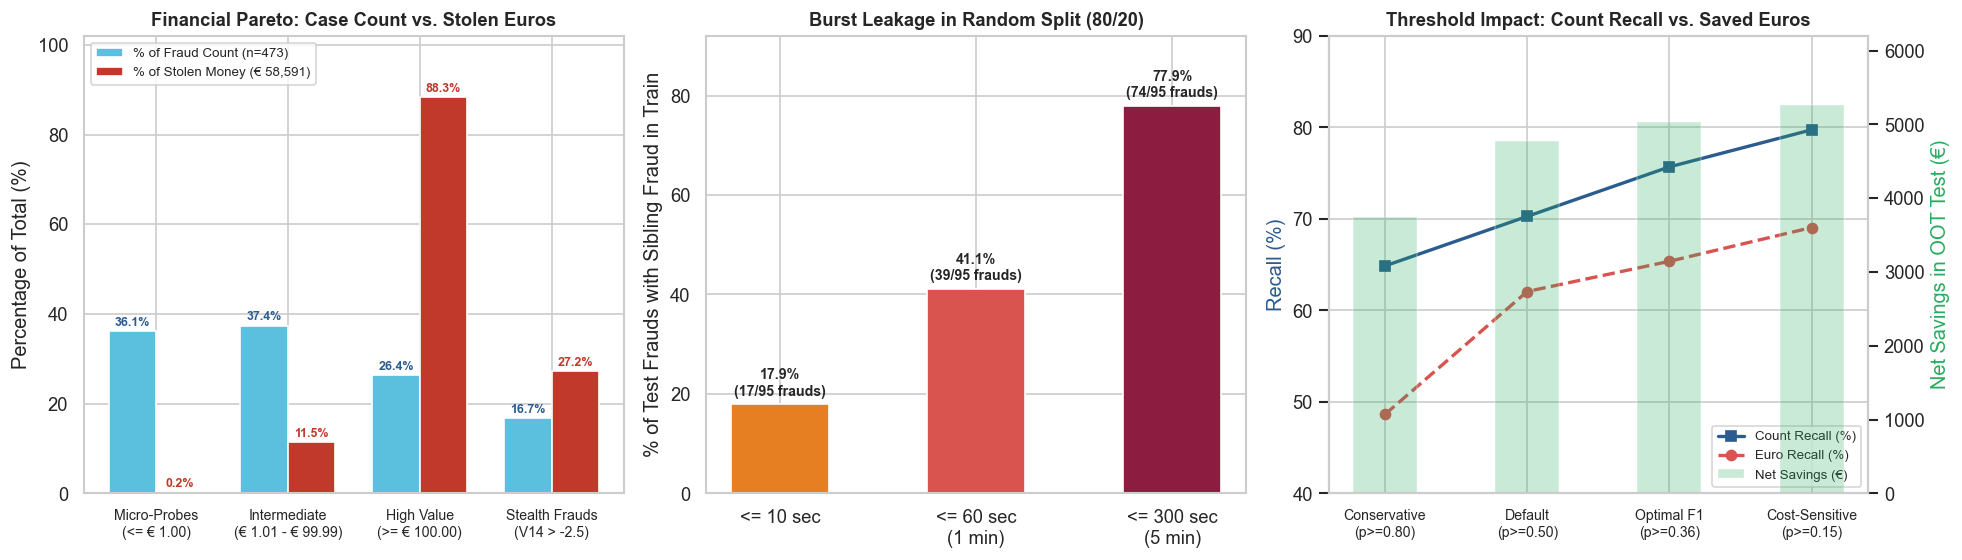

In [21]:
# Triple Panel: Financial Pareto, Burst Leakage in Random Split, and Financial Decision Curve
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

groups = ["Micro-Probes\n(<= € 1.00)", "Intermediate\n(€ 1.01 - € 99.99)", "High Value\n(>= € 100.00)", "Stealth Frauds\n(V14 > -2.5)"]
pct_cnt = [36.15, 37.42, 26.43, 16.70]
pct_eur = [0.22, 11.48, 88.30, 27.19]

x = np.arange(len(groups))
w = 0.36
b1 = axes[0].bar(x - w / 2, pct_cnt, width=w, color="#5bc0de", label="% of Fraud Count (n=473)")
b2 = axes[0].bar(x + w / 2, pct_eur, width=w, color="#c0392b", label="% of Stolen Money (€ 58,591)")
axes[0].set_title("Financial Pareto: Case Count vs. Stolen Euros", fontsize=11, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(groups, fontsize=8.5)
axes[0].set_ylabel("Percentage of Total (%)")
axes[0].set_ylim(0, 102)
axes[0].legend(fontsize=8, loc="upper left")
for bar in b1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h:.1f}%", ha="center", fontsize=7.5, fontweight="bold", color="#2b5c8f")
for bar in b2:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h:.1f}%", ha="center", fontsize=7.5, fontweight="bold", color="#c0392b")

dist_labels = ["<= 10 sec", "<= 60 sec\n(1 min)", "<= 300 sec\n(5 min)"]
leak_pcts = [17.9, 41.1, 77.9]
bars_lk = axes[1].bar(dist_labels, leak_pcts, color=["#e67e22", "#d9534f", "#8c1d40"], width=0.5)
axes[1].set_title("Burst Leakage in Random Split (80/20)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("% of Test Frauds with Sibling Fraud in Train")
axes[1].set_ylim(0, 92)
for bar, cnt in zip(bars_lk, [17, 39, 74]):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 1.8, f"{h:.1f}%\n({cnt}/95 frauds)", ha="center", fontsize=8.5, fontweight="bold")

strat_names = ["Conservative\n(p>=0.80)", "Default\n(p>=0.50)", "Optimal F1\n(p>=0.36)", "Cost-Sensitive\n(p>=0.15)"]
rec_qtd = [64.86, 70.27, 75.68, 79.73]
rec_fin = [48.64, 62.06, 65.36, 69.05]
net_sav = [3743.59, 4775.98, 5030.50, 5265.66]

x3 = np.arange(len(strat_names))
ax3 = axes[2]
ax3_twin = ax3.twinx()
ax3.plot(x3, rec_qtd, marker="s", color="#2b5c8f", linewidth=2, label="Count Recall (%)")
ax3.plot(x3, rec_fin, marker="o", color="#d9534f", linewidth=2, linestyle="--", label="Euro Recall (%)")
ax3_twin.bar(x3, net_sav, color="#27ae60", alpha=0.25, width=0.45, label="Net Savings (€)")
ax3.set_title("Threshold Impact: Count Recall vs. Saved Euros", fontsize=11, fontweight="bold")
ax3.set_xticks(x3)
ax3.set_xticklabels(strat_names, fontsize=8.5)
ax3.set_ylabel("Recall (%)", color="#2b5c8f")
ax3_twin.set_ylabel("Net Savings in OOT Test (€)", color="#27ae60")
ax3.set_ylim(40, 90)
ax3_twin.set_ylim(0, 6200)
ax3_twin.grid(False)
l1, lb1 = ax3.get_legend_handles_labels()
l2, lb2 = ax3_twin.get_legend_handles_labels()
ax3.legend(l1 + l2, lb1 + lb2, loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

### 5.3. Final EDA Consolidation: Blueprint for Preprocessing and Modeling

| Project Pillar | EDA Discovery | Engineering / Modeling Decision |
| :--- | :--- | :--- |
| **1. Cleaning & Duplicates** | `1,081` exact duplicates in the same second (`19` frauds = `3.86%`). | Remove exact duplicates (`283,726` remaining rows) **before** any split to eliminate *data leakage*. |
| **2. `Amount` Feature** | Bimodal distribution (`36.15%` <= `€ 1.00`), magic values (`€ 1.00`, `€ 99.99`, `€ 0.00`, `€ 0.76/0.77`), and ceiling at `€ 2,125.87`. | Create `log1p_amount`, `is_zero_amt`, `is_magic_probe`, and scale with `RobustScaler`. |
| **3. `Time` Feature** | `23.04%` of frauds in the night window (`01h-05h`), *botnet* burst attacks, and `40` *probe → cash-out* chains. | **Drop raw `Time`** (prevents *overfitting* to Day 1 bursts) and use `hour_sin`, `hour_cos`, and `is_night_window`. |
| **4. PCA Components** | `Top 10` concentrate signal; `Bottom 6` are noise; `0.97` collinearity in `V16/V17/V18` within frauds; `16.7%` stealth frauds account for `27.2%` of stolen Euros. | Create `pca_l2_top10` (`AUC = 0.9573`), interactions `V14*V17`, `V16*V17`, and test dropping the 6 noise features. |
| **5. Validation & Metrics** | `77.9%` of random test frauds have a sibling fraud in train within `<= 5 min`; `26.4%` of frauds (`>= € 100`) concentrate **`88.3%` of stolen Euros**. | Evaluate using **Stratified Cross-Validation + Temporal Split (*Out-of-Time*)**, optimizing **AUPRC**, **F1**, and **Net Savings in Euros (`€`)** via *threshold tuning*. |